<a href="https://colab.research.google.com/github/PallaviRajaa/Statistical-Foundation-of-Data-Science/blob/main/Stats11/StatisticsA11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install pymc arviz pandas numpy matplotlib scipy

**Step 1: Load the data and plot sunspot numbers over the years **

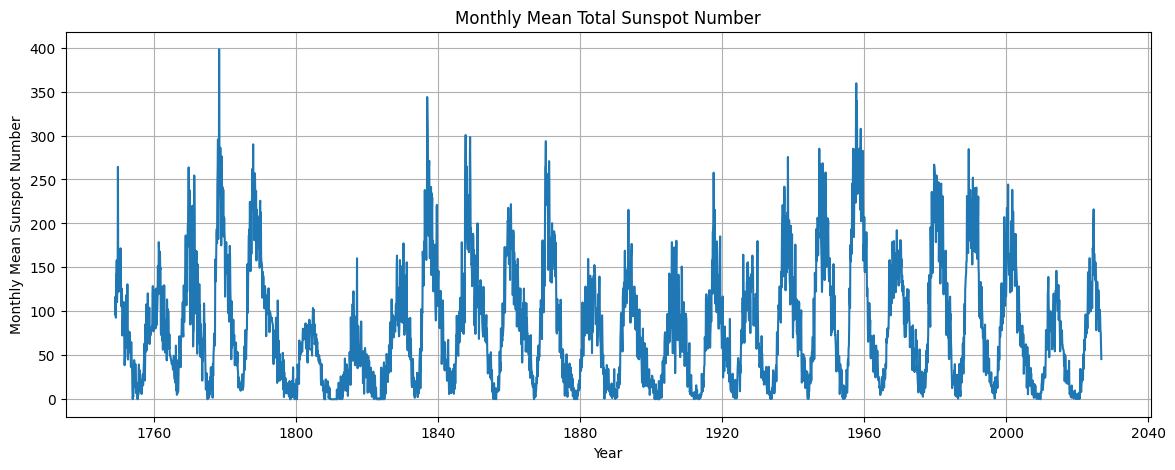

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://www.sidc.be/SILSO/INFO/snmtotcsv.php"

df = pd.read_csv(
    url,
    sep=";",
    header=None,
    names=[
        "year", "month", "date", "sunspots",
        "std", "observations", "indicator"
    ]
)

# Remove missing values
df = df[df["sunspots"] >= 0]

# Create a date column
df["date"] = pd.to_datetime(
    df["year"].astype(str) + "-" +
    df["month"].astype(str),
    format="%Y-%m"
)

# Plot sunspot numbers
plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["sunspots"])

plt.xlabel("Year")
plt.ylabel("Monthly Mean Sunspot Number")
plt.title("Monthly Mean Total Sunspot Number")

plt.grid(True)
plt.show()

The dataset contains several columns, but we are mainly interested in the sunspots column, which contains the monthly mean sunspot number.

We remove missing values and convert the year and month into a proper date format.

Finally, plt.plot() creates a time-series graph showing how sunspot numbers change over time.
Sunspot activity does not remain constant. It increases and decreases periodically, forming repeated peaks and valleys.

**Step 2: Model the phenomenon using a Gamma distribution with a new cycle every 12 years**

   year  month  sunspots  cycle
0  1749      1      96.7      0
1  1749      2     104.3      0
2  1749      3     116.7      0
3  1749      4      92.8      0
4  1749      5     141.7      0


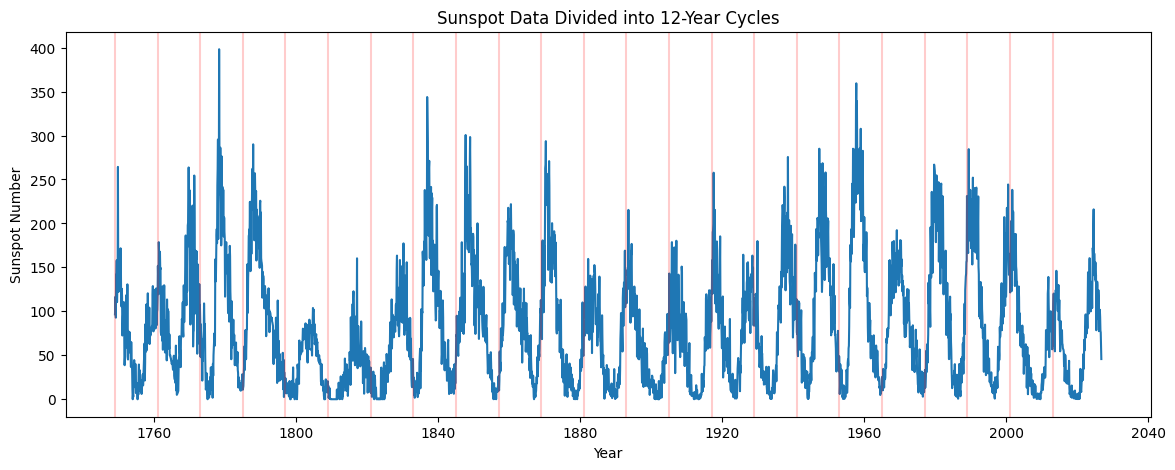

In [ ]:

df["cycle"] = np.arange(len(df)) // 144

print(df[["year", "month", "sunspots", "cycle"]].head())

plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["sunspots"])

for year in range(1749, 2019, 12):
    plt.axvline(
        pd.Timestamp(str(year)),
        color="red",
        alpha=0.2
    )

plt.xlabel("Year")
plt.ylabel("Sunspot Number")
plt.title("Sunspot Data Divided into 12-Year Cycles")

plt.show()

The expression np.arange(len(df)) generates an index for every monthly observation.

Dividing the index by 144 and applying integer division creates a cycle number.

**Step 3: Plot the histogram of sunspot counts**

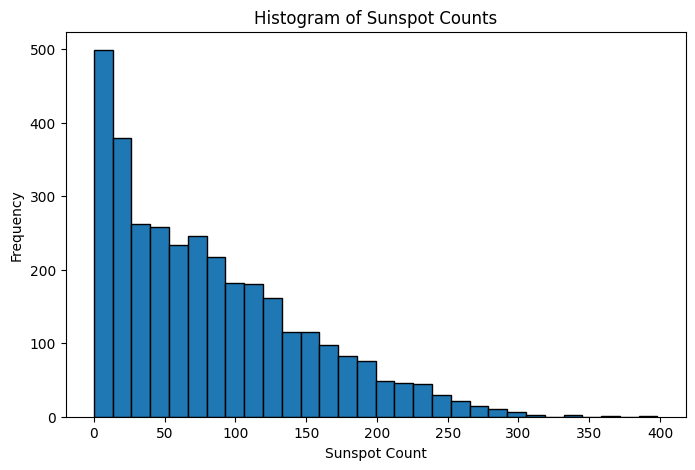

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["sunspots"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Sunspot Count")
plt.ylabel("Frequency")
plt.title("Histogram of Sunspot Counts")

plt.show()

The plt.hist() function divides sunspot values into intervals called bins.

The x-axis represents the sunspot count, while the y-axis represents how frequently those values occur.

This histogram helps us understand whether the data is symmetric, skewed or concentrated around certain values.

Sunspot numbers commonly show a right-skewed distribution because many months have relatively low activity, while some months have very high activity.

**Step 4: Apply MCMC for First 50, All and Last 50 Samples**

In [ ]:
import pymc as pm
import arviz as az

sunspot_data = df["sunspots"].values / 100

sunspot_data[sunspot_data == 0] = 0.001


def run_mcmc(data, group_name):

    with pm.Model() as model:


        a = pm.Gamma("a", alpha=4, beta=1)
        b = pm.Gamma("b", alpha=10, beta=1)


        pm.Gamma(
            "sunspot",
            alpha=a,
            beta=b,
            observed=data
        )


        trace = pm.sample(
            draws=1000,
            tune=1000,
            chains=2,
            initvals={"a": 4, "b": 10},
            random_seed=42
        )

    print(group_name)
    print(az.summary(trace, var_names=["a", "b"]))

    return trace


trace_first = run_mcmc(
    sunspot_data[:50],
    "First 50 Samples"
)


trace_all = run_mcmc(
    sunspot_data,
    "All Samples"
)

trace_last = run_mcmc(
    sunspot_data[-50:],
    "Last 50 Samples"
)

Output()

First 50 Samples
    mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
a  6.636  1.085   4.574    8.592      0.056    0.035     365.0     479.0   
b  6.301  1.071   4.439    8.434      0.057    0.035     356.0     538.0   

   r_hat  
a    1.0  
b    1.0  


Output()

/usr/local/lib/python3.13/dist-packages/pymc/step_methods/hmc/quadpotential.py:316: RuntimeWarning: overflow 
encountered in dot
  return 0.5 * np.dot(x, v_out)

All Samples
    mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
a  0.974  0.021   0.937    1.015      0.001    0.001     525.0     669.0   
b  1.189  0.032   1.126    1.249      0.001    0.001     474.0     687.0   

   r_hat  
a    1.0  
b    1.0  


Output()

Last 50 Samples
    mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
a  9.973  1.572   7.274   13.270      0.087    0.052     328.0     400.0   
b  8.291  1.343   5.814   10.995      0.078    0.047     299.0     385.0   

   r_hat  
a    1.0  
b    1.0  


The function run_mcmc() creates a Gamma probability model.

pm.Gamma() defines the prior distributions for the parameters \(a\) and \(b\).

The observed sunspot values are then fitted using another Gamma distribution.

The pm.sample() function performs MCMC sampling.
- draws=1000 means 1000 posterior samples are collected per chain.
- tune=1000 means 1000 tuning or warm-up iterations are performed.
- chains=2 means two independent chains are used.
- initvals specifies the starting values \(a=4\) and \(b=10\).
Finally, az.summary() displays the estimated mean, standard deviation and other statistics of the parameters.

The three traces allow us to compare how the parameter estimates change depending on the amount and period of data used.

**Step 5: Visualise the traces and histograms of \(a\) and \(b\)**

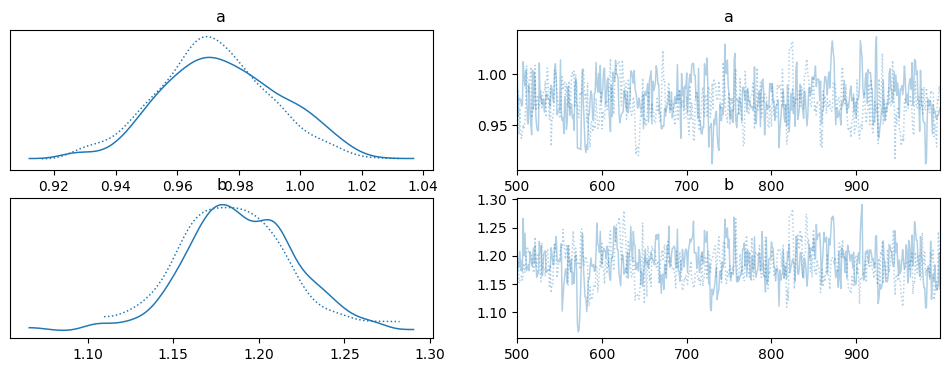

In [ ]:

trace_clean = trace_all.sel(
    draw=slice(500, None)
)


az.plot_trace(
    trace_clean,
    var_names=["a", "b"]
)

plt.show()

The sel() function selects the samples after the burn-in period.

The az.plot_trace() function creates two types of plots for each parameter:
- Trace plot: Shows how the sampled values change across iterations.
- Histogram: Shows the distribution of the sampled parameter values.
A trace plot that fluctuates around a stable region indicates that the chain may have reached a stationary distribution.

The histogram shows the most likely range of values for \(a\) and \(b\).

If the chains mix well and their trace plots look stable, the parameter estimates are generally more reliable.

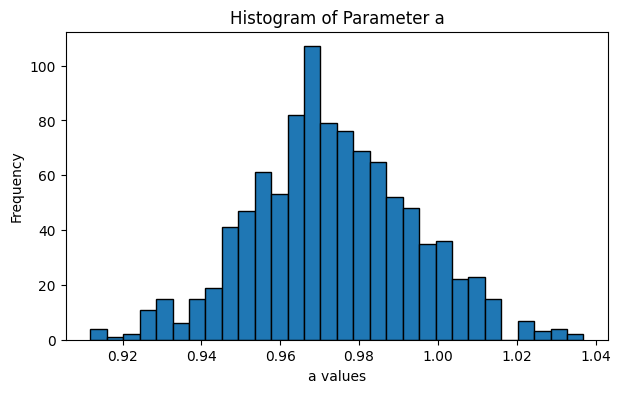

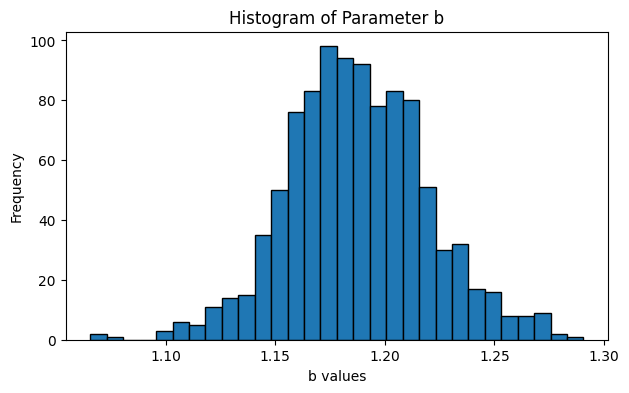

In [ ]:
# Extract posterior samples
a_samples = trace_clean.posterior["a"].values.flatten()
b_samples = trace_clean.posterior["b"].values.flatten()

# Histogram of a
plt.figure(figsize=(7, 4))

plt.hist(a_samples, bins=30, edgecolor="black")

plt.xlabel("a values")
plt.ylabel("Frequency")
plt.title("Histogram of Parameter a")

plt.show()


# Histogram of b
plt.figure(figsize=(7, 4))

plt.hist(b_samples, bins=30, edgecolor="black")

plt.xlabel("b values")
plt.ylabel("Frequency")
plt.title("Histogram of Parameter b")

plt.show()

The posterior samples of \(a\) and \(b\) are extracted from the MCMC trace.

The flatten() function combines samples from different chains into one array.

The two histograms show the posterior distributions of the parameters.

A narrow histogram indicates that the parameter has been estimated with relatively less uncertainty. A wider histogram indicates greater uncertainty.

**Step 6: Predict the values of \(a\) and \(b\), and forecast future sunspot activity**

In [ ]:

a_mean = np.mean(a_samples)
b_mean = np.mean(b_samples)

print("Estimated value of a:", a_mean)
print("Estimated value of b:", b_mean)

# 95% credible intervals
a_interval = np.percentile(a_samples, [2.5, 97.5])
b_interval = np.percentile(b_samples, [2.5, 97.5])

print("95% Credible Interval for a:", a_interval)
print("95% Credible Interval for b:", b_interval)

# Calculate expected sunspot value
predicted_mean = (a_mean / b_mean) * 100

print("Predicted Mean Sunspot Number:", predicted_mean)

Estimated value of a: 0.9732830901551074
Estimated value of b: 1.1872847224165557
95% Credible Interval for a: [0.92928064 1.01378759]
95% Credible Interval for b: [1.12331295 1.25443012]
Predicted Mean Sunspot Number: 81.97554232603304


The np.mean() function calculates the average of the posterior samples.

These averages are used as the estimated values of \(a\) and \(b\).

The np.percentile() function calculates the 95% credible interval. This interval represents the range containing approximately 95% of the posterior probability for each parameter.

The expected sunspot number is calculated using the Gamma distribution's mean:
\[
E(X)=\frac{a}{b}
\]

Since we scaled the original data by 100, we multiply the result by 100 to return to the original sunspot scale.

**Predict sunspot numbers for the next 12 months**

In [ ]:
# Generate posterior predictive samples
np.random.seed(42)

predictions = []

for i in range(len(a_samples)):

    prediction = np.random.gamma(
        shape=a_samples[i],
        scale=1 / b_samples[i]
    ) * 100

    predictions.append(prediction)

predictions = np.array(predictions)

# Display prediction
print("Predicted Sunspot Number:", np.mean(predictions))

print(
    "95% Prediction Interval:",
    np.percentile(predictions, [2.5, 97.5])
)

Predicted Sunspot Number: 80.87232028183854
95% Prediction Interval: [  1.89936924 277.80274391]


The np.random.gamma() function generates random values from the Gamma distribution.

For each posterior sample, we use the corresponding values of \(a\) and \(b\) to generate a possible future sunspot value.

The scale parameter in NumPy's Gamma function is the reciprocal of the rate parameter:
\[
\text{Scale}=\frac{1}{b}
\]

The generated values represent possible future sunspot observations.

The mean of these predictions gives an estimate of future sunspot activity, while the prediction interval shows the uncertainty in the forecast.
